In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [4]:
df = pd.read_csv('Admission_Predict.csv')
df.head()
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         400 non-null    int64  
 1   GRE Score          400 non-null    int64  
 2   TOEFL Score        400 non-null    int64  
 3   University Rating  400 non-null    int64  
 4   SOP                400 non-null    float64
 5   LOR                400 non-null    float64
 6   CGPA               400 non-null    float64
 7   Research           400 non-null    int64  
 8   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 28.3 KB


In [5]:
df.isnull().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

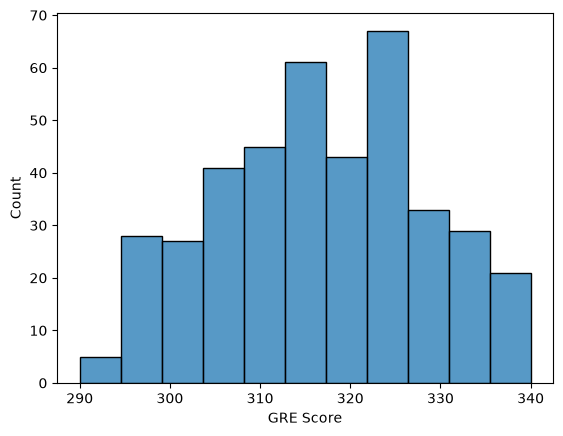

In [6]:
sns.histplot(df["GRE Score"])
plt.show()

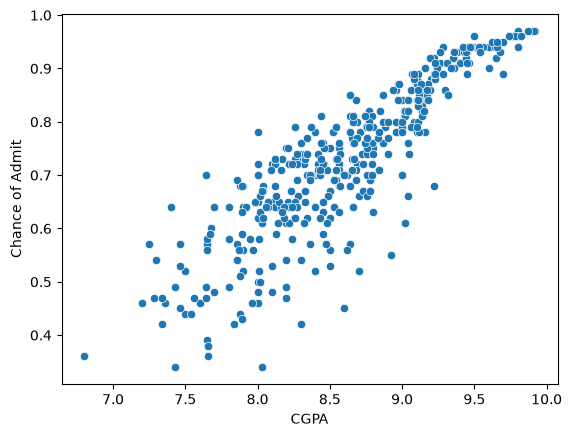

In [7]:
sns.scatterplot(
    x="CGPA",
    y="Chance of Admit",
    data=df
)
plt.show()

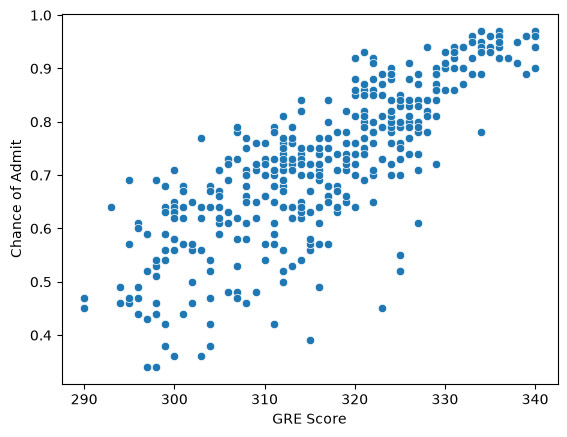

In [8]:
sns.scatterplot(
    x="GRE Score",
    y="Chance of Admit",
    data=df
)
plt.show()

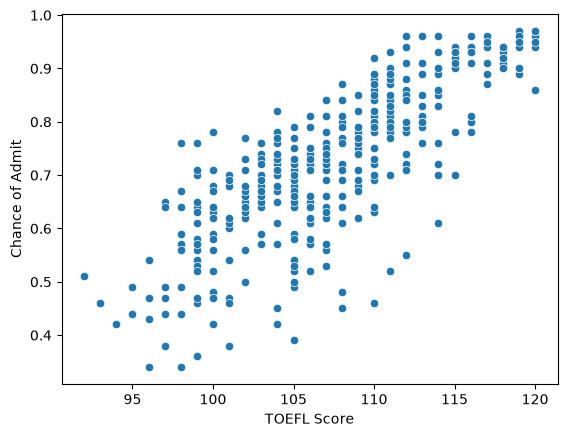

In [9]:
sns.scatterplot(
    x="TOEFL Score",
    y="Chance of Admit",
    data=df
)
plt.show()

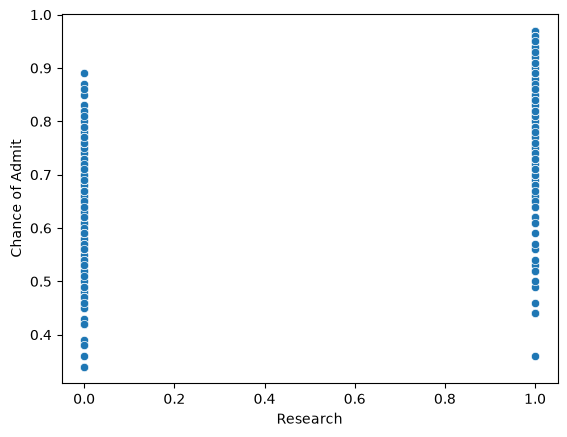

In [10]:
sns.scatterplot(
    x="Research",
    y="Chance of Admit",
    data=df
)
plt.show()

=> Có research thường sẽ có tỉ lệ đỗ cao hơn

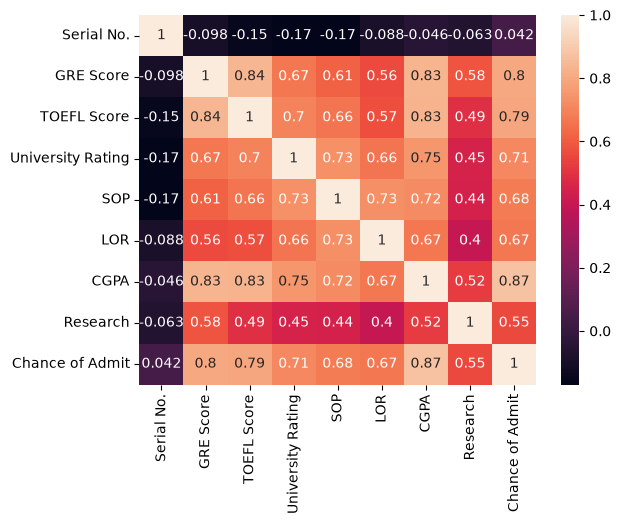

In [11]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True)
plt.show()

=> CGPA có mức độ liên quan cao nhất với COA (Chance of Admit)
   GRE, TOEFL có mức độ tương quan dương với COA
   Việc chọn trường khá qtrong trong tỉ lệ đỗ
   Research chỉ khoảng 0,55 -> là điểm cộng trong việc xét tuyển nhưng không phải trọng yếu

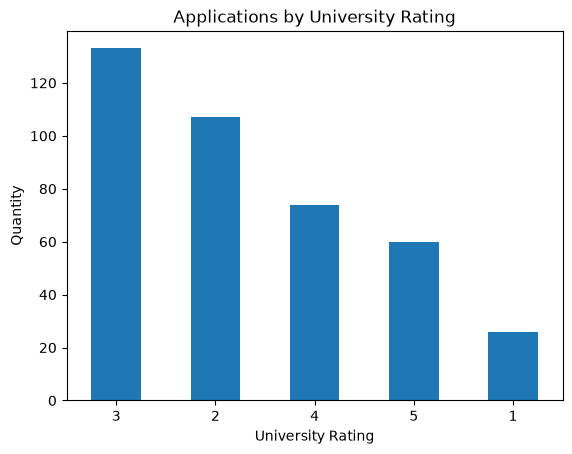

In [12]:
df["University Rating"].value_counts().sort_values(ascending=False).plot(kind="bar")

plt.title("Applications by University Rating")
plt.ylabel("Quantity")
plt.xticks(rotation=0)
plt.show()

=> số học sinh đăng kí vào các trường trung bình khá đông -> đa số là lựa chọn an toàn

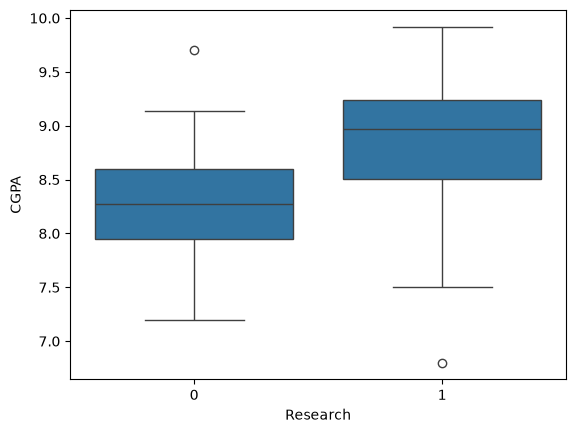

In [13]:
sns.boxplot(
    x="Research",
    y="CGPA",
    data=df
)
plt.show()

=> học sinh có research thường sẽ có điểm CGPA cao hơn sao với những học sinh không có, tuy nhiên vẫn có một số trường hợp đặc biệt. Trung vị của nhóm có Research cao hơn khá rõ rệt (8.2 và 8.9) => research có mối quan hệ tích cực với cgpa

In [14]:
df.groupby("Research")[
    [
        "GRE Score",
        "TOEFL Score",
        "SOP",
        "LOR",
        "CGPA",
        "Chance of Admit"
    ]
].mean()

,GRE Score,TOEFL Score,SOP,LOR,CGPA,Chance of Admit
Research,,,,,,
0,309.491713,104.143646,2.908840,3.060773,8.257182,0.637680
1,322.853881,110.109589,3.805936,3.776256,8.881370,0.795982


=> Những người có kinh nghiệm nghiên cưus thường có xu hướng điểm cao hơn => tỉ lệ đỗ cao hơn

In [15]:
df = df.drop("Serial No.", axis=1)
X = df.drop("Chance of Admit", axis=1)
y = df["Chance of Admit"]

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state=42
)

In [17]:
from sklearn.ensemble import RandomForestRegressor
import pickle
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=4,
    random_state=42
)

In [18]:
model.fit(
    X_train,
    y_train
    )

pickle.dump(model, open("model.pkl","wb"))

In [19]:
train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

print(train_score)
print(test_score)

0.8820602371667127
0.8164940695015735


In [20]:
y_pred = model.predict(X_test)

In [21]:
from sklearn.metrics import r2_score
score = r2_score(
    y_test,
    y_pred
)
score

0.8164940695015735

In [22]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(
    y_test,
    y_pred
)
mae

0.04786646115029407

In [23]:
sto = [[
    320,
    120,
    5,
    4.5,
    4.5,
    9,
    1
]]
model.predict(sto)

c:\Users\admin\OneDrive\Documents\NPS-CSI16-HB-main\NPS-CSI16-HB-main\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


array([0.84829699])

In [24]:
model.feature_names_in_

array(['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR',
       'CGPA', 'Research'], dtype=object)